In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# ConvNeXt: A ConvNet for the 2020s

Every network of this chapter so far is a convolutional network, and until
2020 the best image classifiers were convolutional networks too. In 2021 a
network without convolutions overtook them. A *vision transformer*
[@Dosovitskiy.Beyer.Kolesnikov.ea.2021] cuts the image into a grid of
patches, turns each patch into a vector, and processes this set of vectors
with a stack of identical blocks. Each block has two parts. An *attention*
layer lets every patch take a weighted average of the features of other
patches, with weights computed from the features themselves; a small MLP
then transforms each patch's vector on its own. The Swin Transformer
[@liu2021swin], a vision transformer that computes attention within
local $7 \times 7$ windows of patches and lowers the resolution between
stages as a convnet does, reached 81.3% top-1 accuracy on ImageNet, against
76.1% for a ResNet-50 of similar cost. Did attention cause the gap? If it
did, convolutional networks were obsolete.

The previous section suggests caution. Swin differs from a 2015 ResNet in
many ways besides attention: it was trained with a newer recipe, its stem
slices the image into patches, and it uses another activation, another
normalization, and other stage depths. Which of these differences carried
the improvement? @liu2022convnet answered by experiment. Starting
from a ResNet-50, they applied one Swin-inspired change at a time, measured
ImageNet accuracy after each, and never added attention. The result,
*ConvNeXt*, reaches 82.0%. Its ingredients come from earlier sections: the
training recipe of that section, the depthwise
convolutions and inverted bottlenecks of that section, and
the layer normalization of that section. We read the sequence of
changes, build the network, and train a small ConvNeXt on Fashion-MNIST
against a ResNet-18 with the same number of parameters. Transformers
themselves are the subject of that section.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## The Modernization Roadmap

the table lists the changes in the order the paper
applied them. Each row keeps every change above it, so the accuracies are
cumulative, and the computational cost stays near that of Swin-T, about
4.5 billion multiply-adds per image (the paper's 4.5 GFLOPs).

<!-- tbl-caption:The ConvNeXt modernization roadmap [@liu2022convnet]. ImageNet top-1 accuracy of a ResNet-50 as design changes accumulate; each row includes all rows above it, at roughly constant cost. Swin-T, a transformer of similar cost, reaches 81.3%. -->

| Change | What it means | Top-1 |
|:--|:--|:--|
| (starting point) | ResNet-50 with its 2015 recipe | 76.1% |
| Modern training recipe | 300 epochs, AdamW, Mixup, label smoothing, stochastic depth (that section) | 78.8% |
| Stage ratio | blocks per stage $(3, 4, 6, 3) \to (3, 3, 9, 3)$ | 79.4% |
| Patchify stem | $7 \times 7$ stride-2 convolution plus pooling $\to$ one $4 \times 4$ stride-4 convolution | 79.5% |
| Depthwise convolutions | the $3 \times 3$ convolution becomes depthwise; width grows from 64 to 96 channels | 80.5% |
| Inverted bottleneck | expand $4\times$ inside the block instead of compressing | 80.6% |
| Large kernels | depthwise convolution moved to the front and enlarged to $7 \times 7$ | 80.6% |
| ReLU $\to$ GELU | a smooth activation, as in transformers | 80.6% |
| Fewer activations | one activation per block instead of three | 81.3% |
| Fewer normalizations | one normalization per block instead of three | 81.4% |
| BN $\to$ LN | layer normalization over channels at each position | 81.5% |
| Separate downsampling | an LN plus $2 \times 2$ stride-2 convolution between stages | 82.0% |

The first change, the training recipe, gives the largest single improvement
and does not touch the architecture. It is the recipe effect of
that section: a longer schedule with AdamW and strong
regularization lifts the same ResNet-50 by 2.7 points, and a still longer
600-epoch procedure takes it to 80.4% [@wightman2021resnet]. Of the 5.9
points that separate the 2015 ResNet-50 from ConvNeXt, 2.7 come from
training and 3.2 from the architecture. Papers that compared a well-tuned
transformer against a ResNet trained the 2015 way were therefore comparing
recipes as much as architectures.

### Macro Design

The next two rows change the shape of the network as a whole. Swin-T
distributes its blocks across four stages in the ratio $1{:}1{:}3{:}1$,
spending most of its depth where the feature maps are small and each block
is cheap. Adopting the same ratio turns ResNet-50's $(3, 4, 6, 3)$ blocks
into $(3, 3, 9, 3)$ and adds 0.6 points. The stem changes more. ResNet
begins with a $7 \times 7$ stride-2 convolution followed by max-pooling, a
fourfold reduction computed with overlapping windows. A vision transformer
instead slices the image into non-overlapping patches and multiplies the
pixels of each patch by one shared matrix. That is a convolution whose kernel
size equals its stride (that section), here a $4 \times 4$
convolution with stride 4. This *patchify* stem replaces the ResNet stem with
no loss (79.5%) and produces one feature vector per $4 \times 4$ patch, the
same object a transformer computes.

### Depthwise Convolutions and the Inverted Bottleneck

A transformer block separates two kinds of mixing. Attention combines
information across positions, and the MLP that follows combines the channels
of each position on its own. A convolutional network can separate them the
same way. A *depthwise* convolution applies one $k \times k$ filter to each
channel separately, so it mixes positions but not channels, and a
$1 \times 1$ convolution mixes channels at each position but not positions
(that section). ConvNeXt makes the $3 \times 3$
convolution of the ResNet bottleneck depthwise. That cuts its cost so much
that the network can afford more width: 96 channels in the first stage
instead of 64, matching Swin-T, which brings 80.5%.

The ResNet bottleneck compresses its input with a $1 \times 1$ convolution,
processes it, and expands it again. Once the spatial convolution is
depthwise, the economics reverse, as that section showed for
MobileNetV2: the block can keep a thin stream between blocks and expand it
inside. The transformer's MLP has the same shape, a $1 \times 1$ expansion
by $4\times$, an activation, and a projection back. *Inverting* the
bottleneck this way adds a little (80.6%).

With the dense convolution gone, the kernel size becomes cheap to change. The
depthwise convolution moves to the front of the block, so that it acts on the
thin stream of $c$ channels instead of the $4c$ expanded ones. This alone
costs 0.7 points (to 79.9%), and enlarging the kernel from $3 \times 3$ to
$7 \times 7$ recovers them. A $7 \times 7$ kernel widens the receptive field
as much as three stacked $3 \times 3$ layers (the equation).
VGG chose the stack (that section) because dense kernels cost
$k^2 c_\textrm{i} c_\textrm{o}$ multiply-adds per position. A depthwise
kernel costs $k^2 c$, so going from $3 \times 3$ to $7 \times 7$ multiplies
a small term by $49/9 \approx 5$. The authors report that accuracy saturates
at $7 \times 7$: kernels of $9 \times 9$ and $11 \times 11$ bring no further
improvement at this scale. $7 \times 7$ is also the window size of Swin's
attention.

### Micro Design

The remaining rows change individual layers. GELU
[@Hendrycks.Gimpel.2016], a smooth variant of the ReLU used in Swin and
in BERT- and ViT-style transformers, changes nothing by itself (80.6%). What matters is *how
many* activations and normalizations the block contains. A ResNet bottleneck
follows every convolution with a normalization and an activation: three of
each. A transformer block has one activation, inside its MLP, and one
normalization per part. Keeping only the GELU between the two $1 \times 1$
convolutions adds 0.7 points, more than any other change in this group.
Keeping only one normalization adds 0.1, and making that one a
layer normalization over the channels at each spatial position, instead of a
batch normalization, adds another tenth (81.5%). that section
introduced normalization as an aid to optimization; here fewer such layers,
one per block, train better than three.
the figure shows the block before and after.

![The ResNet-50 bottleneck block and the ConvNeXt block that the roadmap turns it into. Three normalizations and three activations become one of each; the compress-process-expand bottleneck becomes an inverted bottleneck led by a $7 \times 7$ depthwise convolution, and a learnable per-channel layer scale $\boldsymbol{\gamma}$ multiplies the branch before the addition.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-resnet-vs-convnext-block.svg)

Finally, ResNet downsamples inside the first block of each stage by giving
its $3 \times 3$ convolution a stride of 2. Swin uses a separate
patch-merging layer between stages. Adopting the same separation completes
the roadmap at 82.0%: a layer normalization followed by a $2 \times 2$
stride-2 convolution between stages, plus a normalization after the stem and
one before the classifier, which the authors found necessary for stable
training. the figure shows the assembled ConvNeXt-T: a patchify
stem, four stages of $(3, 3, 9, 3)$ blocks at widths $(96, 192, 384, 768)$,
downsampling layers between them, and a head of global average pooling, the
stem-body-head layout this chapter has used since that section.

![ConvNeXt-T. A patchify stem replaces convolution-plus-pooling; stages of 3, 3, 9, and 3 blocks are joined by separate LN plus $2 \times 2$ stride-2 downsampling layers; there is no pooling anywhere in the body.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-convnext.svg)

At equal cost, ConvNeXt-T matches Swin-T, and the paper reports the same for
larger models and for transfer to detection and segmentation. The gap of
2021 came from the training recipe and from design choices other than
attention. The experiment does not show that
convolutions are better: under comparable tuning the two families reach
similar accuracy.

## Implementation

The roadmap removed more than it added, so the block is short.

### The ConvNeXt Block

The block applies, in order, a $7 \times 7$ depthwise convolution, a layer
normalization, a $1 \times 1$ convolution that expands the channels
$4\times$, a GELU, and a $1 \times 1$ convolution that projects back, and it
adds the result to its input. Two details of the paper's training setup come
with it. *Layer scale* [@touvron2021cait] multiplies the branch by a
learnable vector $\boldsymbol{\gamma}$, one entry per channel, initialized
to $10^{-6}$. Every block then starts close to the identity, and the network
begins training as a shallow function. *Stochastic depth*
(that section) drops the whole branch of a block, for each
example independently, with probability $p$ during training and scales the
kept branches by $1/(1-p)$, so that the expected output is unchanged.

The layer normalization of ConvNeXt normalizes the channels at each spatial
position separately, as a transformer normalizes each patch vector. In a
channels-last layout (examples, height, width, channels) this is the default
layer normalization over the last axis, and a $1 \times 1$ convolution is a
linear layer applied to that axis. Following the paper, every convolution
and linear layer starts with weights drawn from a normal distribution with
standard deviation 0.02 and zero biases.
<!-- d2l:prose id=convnext-md-3 fw=tensorflow, jax -->

Images are stored channels-last, so the block uses the library's layer
normalization and dense layers directly.

In [2]:
class ConvNeXtBlock(nnx.Module):
    """Depthwise 7x7, LN, 1x1 expand, GELU, 1x1 project, scaled residual."""
    def __init__(self, dim, drop_prob=0.0, layer_scale=1e-6, rngs=None):
        rngs = (nnx.Rngs(params=d2l.get_key(), dropout=d2l.get_key())
                if rngs is None else rngs)
        w_init = nnx.initializers.normal(0.02)
        self.dwconv = nnx.Conv(dim, dim, kernel_size=(7, 7), padding='same',
                               feature_group_count=dim, kernel_init=w_init,
                               rngs=rngs)
        self.norm = nnx.LayerNorm(dim, epsilon=1e-6, rngs=rngs)
        self.pwconv1 = nnx.Linear(dim, 4 * dim, kernel_init=w_init,
                                  rngs=rngs)
        self.pwconv2 = nnx.Linear(4 * dim, dim, kernel_init=w_init,
                                  rngs=rngs)
        self.gamma = nnx.Param(layer_scale * jnp.ones(dim))
        self.drop_prob, self.rngs = drop_prob, rngs
        self.deterministic = False

    def set_view(self, *, deterministic):
        self.deterministic = deterministic

    def __call__(self, X):
        Y = self.norm(self.dwconv(X))
        Y = self.pwconv2(nnx.gelu(self.pwconv1(Y), approximate=False))
        return X + d2l.drop_path(self.rngs.dropout(), self.gamma * Y,
                                 self.drop_prob, not self.deterministic)

### The Full Network

The network is the loop over a tuple of (depth, channels) pairs of
that section once more. The stem is the patchify convolution plus a
layer normalization. Between stages sits the separate downsampling layer, a
layer normalization followed by a $2 \times 2$ stride-2 convolution; there is
no pooling in the body. Following the paper, the stochastic-depth
probability grows linearly from zero at the first block to its maximum at the
last. For Fashion-MNIST we use the widths $(40, 80, 160, 320)$ and depths
$(2, 2, 6, 2)$ of ConvNeXt-atto, the smallest variant in common use; the
third stage is the deepest, as in ConvNeXt-T.

In [3]:
class ConvNeXt(d2l.Classifier):
    def __init__(self, arch=((2, 40), (2, 80), (6, 160), (2, 320)),
                 lr=2e-3, num_classes=10, drop_path_max=0.1, rngs=None):
        super().__init__()
        self.save_hyperparameters(ignore=['rngs'])
        rngs = (nnx.Rngs(params=d2l.get_key(), dropout=d2l.get_key(),
                         mixup=d2l.get_key()) if rngs is None else rngs)
        self.rngs = rngs
        w_init = nnx.initializers.normal(0.02)
        depths = [d for d, c in arch]
        rates = jnp.linspace(0, drop_path_max, sum(depths)).tolist()
        layers = [nnx.Conv(1, arch[0][1], kernel_size=(4, 4), strides=(4, 4),
                           kernel_init=w_init, rngs=rngs),
                  nnx.LayerNorm(arch[0][1], epsilon=1e-6, rngs=rngs)]
        c_prev, b = arch[0][1], 0
        for i, (depth, c) in enumerate(arch):
            if i > 0:  # Separate downsampling layer between stages
                layers += [nnx.LayerNorm(c_prev, epsilon=1e-6, rngs=rngs),
                           nnx.Conv(c_prev, c, kernel_size=(2, 2),
                                    strides=(2, 2), kernel_init=w_init,
                                    rngs=rngs)]
            for _ in range(depth):
                layers.append(ConvNeXtBlock(c, drop_prob=rates[b], rngs=rngs))
                b += 1
            c_prev = c
        layers += [global_avg_pool,
                   nnx.LayerNorm(c_prev, epsilon=1e-6, rngs=rngs),
                   nnx.Linear(c_prev, num_classes, kernel_init=w_init,
                              rngs=rngs)]
        self.net = nnx.Sequential(*layers)

def global_avg_pool(X):  # Average over height and width (NHWC)
    return X.mean(axis=(1, 2))

We train on Fashion-MNIST upsampled to $64 \times 64$. Such an input leaves
the stem as a $16 \times 16$ map, and the three downsampling layers reduce
it to $8 \times 8$, $4 \times 4$, and finally $2 \times 2$ before the head
pools it away. We check the output shape
and count the parameters.

In [4]:
model = ConvNeXt()
assert model(jnp.zeros((1, 64, 64, 1))).shape == (1, 10)
d2l.num_params(model)

3376450

The network has 3,376,450 parameters, about a third of the 11.2 million of
the ResNet-18 that that section trained on Fashion-MNIST. Because a
single wrongly sized layer changes it, the count is a sensitive check of any
reimplementation, ours included.

## A Parameter-Matched Comparison

ConvNeXt's design was selected on ImageNet at $224 \times 224$. Does it also
help on small grayscale images? We train our ConvNeXt against a control with
the same number of parameters: a ResNet-18 whose base width is reduced from
64 to 35 channels. Both use the compact modern recipe B of
that section: AdamW with weight decay 0.05, a learning rate
that rises linearly from zero to $2 \times 10^{-3}$ and then decays to zero
along a cosine, label smoothing of 0.1, and Mixup with $\alpha = 0.2$. Two
settings differ from that section: the networks train for 20 epochs on the
full training set instead of 45 epochs on 10,000 images, and the warmup
covers the first 10% of the steps instead of three epochs. We set the
stochastic-depth rate of ConvNeXt to zero because the ResNet control has no
such mechanism.

The class `ModernRecipe` below packages that recipe as a mixin, so that one
copy serves both models: it supplies the optimizer with its schedule and the
training step, and any classifier that stores its learning rate `lr` and its
total number of optimization steps `num_steps` can inherit it. The
validation loss stays the plain cross-entropy of `Classifier`, so it means
the same in every section.

In [5]:
class ModernRecipe:
    """AdamW, linear warmup then cosine decay, label smoothing, Mixup."""
    def configure_optimizers(self):
        warmup = self.num_steps // 10
        schedule = lambda t: self.lr * d2l.cosine_warmup(t, self.num_steps,
                                                         warmup)
        return optax.adamw(schedule, weight_decay=0.05)

    def training_step(self, batch):
        X, y_a, y_b, lam = d2l.mixup(self.rngs.mixup(), *batch, alpha=0.2)
        Y_hat = self(X)
        smooth = lambda y: optax.smooth_labels(
            jax.nn.one_hot(y, Y_hat.shape[1]), 0.1)
        loss = lambda y: optax.softmax_cross_entropy(Y_hat, smooth(y)).mean()
        return lam * loss(y_a) + (1 - lam) * loss(y_b)

class ModernConvNeXt(ModernRecipe, ConvNeXt):
    def __init__(self, num_steps, lr=2e-3):
        super().__init__(lr=lr, drop_path_max=0.0)
        self.num_steps = num_steps

The control stacks the `Residual` blocks of that section in the
layout of ResNet-18: a $7 \times 7$ stride-2 stem with max-pooling, four
stages of two blocks each with 35, 70, 140, and 280 channels, and a
global-average-pooling head.

In [6]:
class CompactResNet18(ModernRecipe, d2l.Classifier):
    """ResNet-18 with base width 35 instead of 64, trained by the recipe."""
    def __init__(self, num_steps, lr=2e-3, num_classes=10, base=35,
                 rngs=None):
        super().__init__()
        self.save_hyperparameters(ignore=['rngs'])
        rngs = (nnx.Rngs(params=d2l.get_key(), mixup=d2l.get_key())
                if rngs is None else rngs)
        self.rngs = rngs
        w_init = nnx.initializers.variance_scaling(2.0, 'fan_in', 'normal')
        layers = [nnx.Conv(1, base, (7, 7), strides=(2, 2), padding=3,
                           use_bias=False, kernel_init=w_init, rngs=rngs),
                  nnx.BatchNorm(base, momentum=0.9, use_fast_variance=False,
                                rngs=rngs), nnx.relu, max_pool]
        c_prev = base
        for i, c in enumerate((base, 2 * base, 4 * base, 8 * base)):
            for j in range(2):
                down = i > 0 and j == 0
                layers.append(d2l.Residual(
                    c, use_1x1conv=down, strides=(2, 2) if down else (1, 1),
                    in_channels=c_prev, rngs=rngs))
                c_prev = c
        layers += [global_avg_pool,
                   nnx.Linear(c_prev, num_classes, kernel_init=w_init,
                              rngs=rngs)]
        self.net = nnx.Sequential(*layers)

def max_pool(X):  # 3x3 windows, stride 2, padding 1
    return nnx.max_pool(X, (3, 3), (2, 2), padding=((1, 1), (1, 1)))

We train both networks for 20 epochs on the full Fashion-MNIST training set
at $64 \times 64$ and record the validation accuracy after the last epoch.

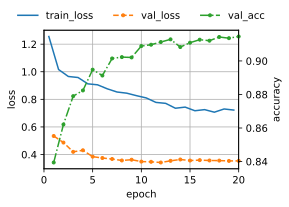

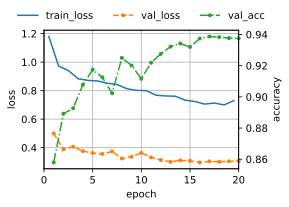

In [7]:
data = d2l.FashionMNIST(batch_size=128, resize=(64, 64))
num_steps = 20 * len(data.train_dataloader())
models, accuracy = {}, {}
for name, cls in (('ConvNeXt', ModernConvNeXt),
                  ('compact ResNet-18', CompactResNet18)):
    models[name] = cls(num_steps)
    trainer = d2l.Trainer(max_epochs=20, num_gpus=1)
    trainer.fit(models[name], data)
    accuracy[name] = trainer.history['val_acc'][-1]

In [8]:
for name, model in models.items():
    print(f'{name}: {d2l.num_params(model):,} parameters, '
          f'validation accuracy {accuracy[name]:.3f}')

ConvNeXt: 3,376,450 parameters, validation accuracy 0.915
compact ResNet-18: 3,346,675 parameters, validation accuracy 0.938


<!-- tbl-caption:Validation accuracy of the scaled-down ConvNeXt and a ResNet-18 with the same number of parameters and nearly the same multiply-adds per $64 \times 64$ image, after 20 epochs of the modern recipe on Fashion-MNIST (rounded). -->

| Model | Parameters | Multiply-adds | Validation accuracy |
|:--|--:|--:|--:|
| ConvNeXt | 3,376,450 | 44.3M | ≈ 91.5% |
| Compact ResNet-18 | 3,346,675 | 43.2M | ≈ 94% |

The compact ResNet-18 is ahead by about two points in every run, and both
validation curves level off over the last epochs as the learning rate decays
to zero. The result is specific to this setting. Every change on the roadmap
was selected on 1.3 million ImageNet images at $224 \times 224$. Our control
matches both the parameters and the arithmetic: counting the multiply-adds of
every convolution and linear layer for one $64 \times 64$ image gives 44.3
million for the ConvNeXt and 43.2 million for the ResNet. It does not match
the running time. What the experiment shows is that ConvNeXt's design choices
do not transfer automatically to a small grayscale task; it does not rank
convolutional architectures in general.

## Limits and Open Problems

ConvNeXt answers one question, which design choices closed the gap of 2021,
and leaves two open. The first is pretraining. Large vision models are now
often pretrained without labels, for instance as *masked autoencoders*
[@he2022masked] that hide most patches of an image and learn to
reconstruct them. Hiding patches is natural for a network that treats the
image as a set of patches and awkward for a convolution that slides across
the holes. ConvNeXt V2 [@woo2023convnextv2] makes it work with sparse
convolutions that skip the masked regions, and in doing so finds that many
channels of the pretrained V1 block become inactive or copies of each other.
Its remedy, *Global Response Normalization*, rescales each channel by its
overall response relative to the other channels; problem
5 implements it.

The second is spatial context. A $7 \times 7$ kernel sees a small window, and
global attention, as in the original vision transformer, lets every
position read from every other. Depthwise kernels of $31 \times 31$
[@ding2022replknet], trained with the re-parameterization of
that section, widen the window further and help most in
detection and segmentation. Whether fixed large kernels, convolutions that
learn where to sample, or attention is the better way to see the whole image
at a given cost is still open.

## Summary

ConvNeXt is a controlled experiment wearing an architecture's name. Starting
from a ResNet-50, it applied the design choices of the Swin Transformer one
at a time and kept those that helped: a modern training recipe, a
$1{:}1{:}3{:}1$ stage ratio, a patchify stem, depthwise convolutions in an
inverted bottleneck led by a $7 \times 7$ kernel, one GELU and one layer
normalization per block, and separate downsampling layers. The result matches Swin-T at
equal cost without attention, and 2.7 of its 5.9 points over the 2015
ResNet-50 come from the recipe alone. Its block separates mixing across
positions (the depthwise convolution) from mixing across channels (the
$1 \times 1$ expansion and projection), as a transformer block separates
attention from its MLP. Choices selected at ImageNet scale need not transfer
to other data: on upsampled Fashion-MNIST, a ResNet-18 with the same number
of parameters is about two points more accurate than our ConvNeXt.

## Exercises

1. **Roadmap ablations.** The roadmap in the table
   applies its changes in one fixed order, and each row's gain is measured
   with every earlier change in place.
    1. Just before the "Large kernels" row, each block expands its residual
       width $c$ to $4c$ with a $1 \times 1$ convolution, applies a
       $3 \times 3$ depthwise convolution to the $4c$ channels, and projects
       back to $c$ with a second $1 \times 1$ convolution. The row first
       moves the depthwise convolution in front of the expansion, where it
       acts on $c$ channels, and then enlarges its kernel to $7 \times 7$.
       Count the multiply-adds per spatial position of the depthwise
       convolution before the move, after the move, and after the
       enlargement. Compare the net change over the row with the change
       that enlarging the kernel to $7 \times 7$ in place, on the $4c$
       channels, would have caused.
    1. Choose two rows whose gains you expect to depend on their order, and
       design the additional runs that would measure the interaction.

1. **Where the parameters live.**
    1. For the `ConvNeXt` of this section, compute the fraction of
       parameters in the depthwise convolutions, in the $1 \times 1$
       expansions and projections, in the normalizations and layer-scale
       vectors inside the blocks, in the downsampling layers, and in the
       stem and head. Check that the total is 3,376,450.
    1. Express the parameter count of a `ConvNeXtBlock` and of a `Residual`
       block of that section without the $1 \times 1$ shortcut as
       functions of the width $c$. Which design decision makes the ConvNeXt
       block cheaper, and by what factor for large $c$?

1. **Normalization axes.** The activations entering a normalization layer
   form a minibatch of $n$ images, each with $c$ channels on an
   $h \times w$ map. Consider three layers: batch normalization, the
   per-position layer normalization of `ConvNeXtBlock`, and a layer
   normalization over all $chw$ values of an image with one learnable scale
   and one learnable shift per value.
    1. For each layer, state which values share one mean and variance, and
       count its learnable parameters.
    1. A network trained on $64 \times 64$ images is evaluated on
       $224 \times 224$ images. Which of the three layers can be applied to
       the larger images with their trained parameters unchanged? Explain.

1. [code] **Layer scale.** Under the recipe of the comparison in
   the table, train `ConvNeXt` with $\boldsymbol{\gamma}$
   initialized to $10^{-6}$ (the default), with $\boldsymbol{\gamma}$
   initialized to $1$, and with layer scale removed, and compare the
   training curves. Layer scale at $10^{-6}$ and stochastic depth
   (the equation of that section) both
   make the network effectively shallower than its block count. For each
   mechanism, explain how it does so, state when during training it acts,
   and state whether it changes the network used at evaluation.

1. [code] **Global Response Normalization.** ConvNeXt V2
   [@woo2023convnextv2] inserts GRN after the GELU of the block and
   removes layer scale. For a feature map $\mathbf{X}$ with $C$ channels,
   let $g_c$ be the $\ell_2$ norm of channel $c$ over all spatial positions
   and $\bar{g}$ the mean of $g_1, \ldots, g_C$. GRN rescales each channel
   by its normalized response and adds a learnable per-channel affine term
   and a residual,
   $$\mathrm{GRN}(\mathbf{X})_c = \gamma_c \frac{g_c}{\bar{g} + \epsilon} \mathbf{X}_c + \beta_c + \mathbf{X}_c,$$
   with a small $\epsilon$ against division by zero ($10^{-6}$ in the
   paper's code), and with $\gamma_c$ and $\beta_c$ initialized to zero so
   that the layer starts as the identity.
    1. Implement GRN in about five lines and insert it into `ConvNeXtBlock`
       after the GELU, dropping layer scale.
    1. Retrain under the recipe of the comparison in
       the table and compare
       the validation accuracy.

1. [code] **Depthwise kernel size.** ● Under the recipe of the comparison in
   the table, train `ConvNeXt` with $3 \times 3$ and
   with $11 \times 11$ depthwise convolutions that leave the feature-map
   size unchanged, and compare accuracy, parameter count, and time per
   epoch against the $7 \times 7$ baseline. Does accuracy saturate at
   $7 \times 7$ here as @liu2022convnet report on ImageNet? How
   does the change in time per epoch compare with the change in the
   depthwise term's arithmetic, and why?

1. [code] **Channel redundancy.** ● Take the `ConvNeXt` trained with GRN in
   problem 5 and the one
   trained without it under the same recipe. Measure the channel redundancy
   that GRN was designed to prevent, at the input of the second $1 \times 1$
   convolution of every block. For each validation image, flatten each
   channel's map into a vector over the spatial positions, and average the
   cosine similarity over all pairs of channels. Average over the images
   and compare the networks with and without GRN block by block. In which
   stages, if any, does GRN make the channels less similar?

1. [code] **Recipe downgrade.** ● The comparison in
   the table trains two architectures under the modern
   recipe. Complete the ablation square by training both models under
   recipe A of that section: SGD with momentum, step
   decay, and neither Mixup nor label smoothing, with the learning rate
   retuned. How much of each network's accuracy survives the downgrade, and
   does the recipe help both architectures equally? Compare the size of the
   effect with the 2.7 points that the "Modern training recipe" row of
   the table attributes to the recipe on ImageNet.

[Discussions](https://d2l.discourse.group/t/36762)